# 01 — Análise exploratória (EDA)

**Tech Challenge — Fase 2 | POSTECH Data Analytics | Grupo 08**

Este notebook examina as duas tabelas do dataset *Credit Card Approval Prediction*:

- `application_record.csv` — cadastro dos clientes;
- `credit_record.csv` — histórico mensal de pagamento (`STATUS`).

Escopo: distribuições, outliers, correlações e balanceamento. Nenhuma transformação é gravada aqui; o tratamento acontece em `02_preprocessamento.ipynb`.

**Entradas:** `data/raw/application_record.csv`, `data/raw/credit_record.csv`.
**Saídas:** tabelas de correlação em `data/processed/analise_correlacao/`.

In [2]:
# Configuração comum a todos os notebooks do projeto
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

SEMENTE = 42  # semente fixa usada em todo o projeto

# Funciona rodando a partir de notebooks/ ou da raiz do repositório.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = RAIZ / "data" / "raw"              # arquivos brutos (não versionados)
PROCESSED = RAIZ / "data" / "processed"  # artefatos intermediários (não versionados)
PROCESSED.mkdir(parents=True, exist_ok=True)

## 1. Cadastro: dimensão, tipos e valores ausentes

Verificações iniciais da tabela `application_record`: tamanho, tipos, duplicidades e nulos.

In [3]:
# ============================================================
# 1. CARREGAR A TABELA application_record
# ============================================================
import os

banco_dados = RAW / "application_record.csv"

if os.path.exists(banco_dados):
    print("Arquivo encontrado. Continuando...")

    df = pd.read_csv(banco_dados)

    print("Base carregada com sucesso.")
    print("Dimensão:", df.shape)

else:
    print("ERRO: arquivo não encontrado.")
    print("Verifique se o caminho está correto:")
    print(banco_dados)


# ============================================================
# 3. VERIFICAÇÕES INICIAIS DA BASE
# ============================================================

# Exibe a quantidade de linhas e colunas.
print("Dimensão da base:", df.shape)

# Mostra as primeiras cinco linhas para uma inspeção visual.
display(df.head())

# Mostra os nomes das colunas.
print("\nColunas:")
print(df.columns.tolist())

# Mostra tipos das variáveis, quantidade de valores não nulos e uso aproximado de memória.
print("\nInformações gerais:")
df.info(memory_usage="deep")

# ============================================================
# 4. PRESERVAR UMA REFERÊNCIA DOS DADOS ORIGINAIS
# ============================================================

# Cria uma cópia da base carregada antes de iniciar transformações exploratórias.
# Isso é útil para conferência durante o desenvolvimento.
df_original = df.copy()


# ============================================================
# 5. PADRONIZAR NOMES DAS COLUNAS
# ============================================================

# Remove espaços no início e no fim, converte nomes para minúsculas e troca
# espaços internos por sublinhado. Isso reduz erros de digitação no código.
df.columns = (
    df.columns
      .astype(str)
      .str.strip()
      .str.lower()
      .str.replace(" ", "_", regex=False)
)

# Mostra os nomes após a padronização.
print("\nColunas padronizadas:")
print(df.columns.tolist())


# ============================================================
# 6. DIAGNÓSTICO DE QUALIDADE DOS DADOS
# ============================================================

# Conta quantos registros completamente duplicados existem.
duplicados = df.duplicated().sum()

# Exibe a quantidade encontrada.
print(f"\nRegistros duplicados: {duplicados}")

# Conta valores ausentes em cada coluna.
nulos = df.isna().sum()

# Calcula o percentual de valores ausentes em cada coluna.
percentual_nulos = (df.isna().mean() * 100).round(2)

# Junta quantidade e percentual em uma única tabela.
resumo_nulos = pd.DataFrame({
    "quantidade_nulos": nulos,
    "percentual_nulos": percentual_nulos
})

# Ordena as colunas começando pelas que têm maior percentual de ausência.
resumo_nulos = resumo_nulos.sort_values(
    "percentual_nulos",
    ascending=False
)

# Exibe apenas colunas que possuem pelo menos um valor ausente.
display(resumo_nulos[resumo_nulos["quantidade_nulos"] > 0])

Arquivo encontrado. Continuando...
Base carregada com sucesso.
Dimensão: (438557, 18)
Dimensão da base: (438557, 18)


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0



Colunas:
['ID', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'FLAG_MOBIL', 'FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS']

Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  str    
 2   FLAG_OWN_CAR         438557 non-null  str    
 3   FLAG_OWN_REALTY      438557 non-null  str    
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  str    
 7   NAME_EDUCATION_TYPE  438557 non-null  str    
 8   NAME_FAMILY_STATUS   438557 non-null  str    

,quantidade_nulos,percentual_nulos
occupation_type,134203,30.6


## 2. Distribuições e outliers do cadastro

> Célula adicionada na divisão do notebook original (o Colab não tinha essa análise). Sem saídas gravadas: execute para gerar.

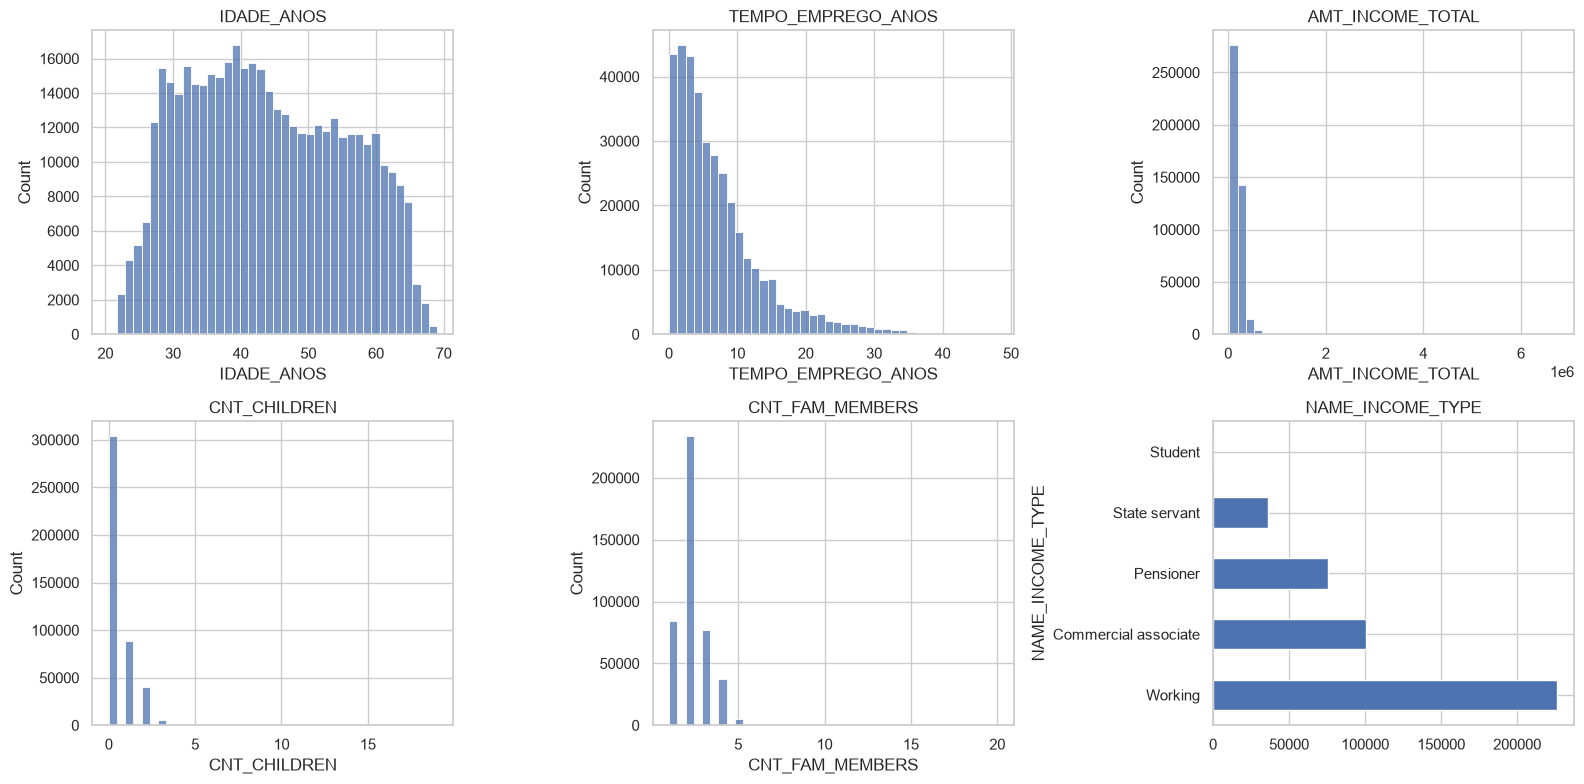

,validos,q1,q3,limite_inferior,limite_superior,outliers,outliers_%,maximo
IDADE_ANOS,438510.0,34.26,53.34,5.64,81.97,0.0,0.00,69.0
TEMPO_EMPREGO_ANOS,363186.0,2.51,9.62,-8.16,20.28,20102.0,5.53,48.0
AMT_INCOME_TOTAL,438510.0,121500.00,225000.00,-33750.00,380250.00,19106.0,4.36,6750000.0
CNT_CHILDREN,438510.0,0.00,1.00,-1.50,2.50,6074.0,1.39,19.0
CNT_FAM_MEMBERS,438510.0,2.00,3.00,0.50,4.50,5689.0,1.30,20.0


Registros com DAYS_EMPLOYED = 365243 (código de 'sem emprego'): 75324


In [4]:
# Distribuições e outliers do cadastro (célula adicionada na divisão do notebook original)
import matplotlib.pyplot as plt
import seaborn as sns

cadastro_eda = (
    pd.read_csv(RAW / "application_record.csv")
    .drop_duplicates(subset="ID", keep="first")
)

# Variáveis em dias viram anos; 365243 é código especial de "sem emprego".
eda = pd.DataFrame({
    "IDADE_ANOS": -cadastro_eda["DAYS_BIRTH"] / 365.25,
    "TEMPO_EMPREGO_ANOS": -cadastro_eda["DAYS_EMPLOYED"].where(cadastro_eda["DAYS_EMPLOYED"] <= 0) / 365.25,
    "AMT_INCOME_TOTAL": cadastro_eda["AMT_INCOME_TOTAL"],
    "CNT_CHILDREN": cadastro_eda["CNT_CHILDREN"],
    "CNT_FAM_MEMBERS": cadastro_eda["CNT_FAM_MEMBERS"],
})

sns.set_theme(style="whitegrid")
fig, eixos = plt.subplots(2, 3, figsize=(16, 8))
eixos = eixos.ravel()

for eixo, coluna in zip(eixos, eda.columns):
    sns.histplot(eda[coluna].dropna(), bins=40, ax=eixo)
    eixo.set_title(coluna)

cadastro_eda["NAME_INCOME_TYPE"].value_counts().plot.barh(ax=eixos[-1])
eixos[-1].set_title("NAME_INCOME_TYPE")
plt.tight_layout()
plt.show()


# Outliers pelo critério do intervalo interquartil (1,5 x IQR). Nada é removido.
def resumo_outliers(serie):
    s = serie.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = int(((s < inferior) | (s > superior)).sum())
    return {
        "validos": len(s), "q1": q1, "q3": q3,
        "limite_inferior": inferior, "limite_superior": superior,
        "outliers": n, "outliers_%": round(100 * n / len(s), 2),
        "maximo": s.max(),
    }


OUTLIERS = pd.DataFrame({c: resumo_outliers(eda[c]) for c in eda.columns}).T
display(OUTLIERS.round(2))

print(
    "Registros com DAYS_EMPLOYED = 365243 (código de 'sem emprego'):",
    int((cadastro_eda["DAYS_EMPLOYED"] == 365243).sum()),
)

## 3. Correlações

Pearson e Spearman entre as variáveis numéricas (idade e tempo de emprego em anos), mais as categorias expandidas em indicadores 0/1.

Linhas: 438,557 | Colunas: 18


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0



Diagnóstico das colunas:


,tipo,ausentes,ausentes_%,valores_distintos
ID,int64,0,0.0,438510
CODE_GENDER,str,0,0.0,2
FLAG_OWN_CAR,str,0,0.0,2
FLAG_OWN_REALTY,str,0,0.0,2
CNT_CHILDREN,int64,0,0.0,12
AMT_INCOME_TOTAL,float64,0,0.0,866
NAME_INCOME_TYPE,str,0,0.0,5
NAME_EDUCATION_TYPE,str,0,0.0,5
NAME_FAMILY_STATUS,str,0,0.0,5
NAME_HOUSING_TYPE,str,0,0.0,6


Linhas completamente duplicadas: 0
IDs repetidos: 47
Registros com DAYS_EMPLOYED = 365243: 75329

Colunas constantes removidas: ['FLAG_MOBIL']


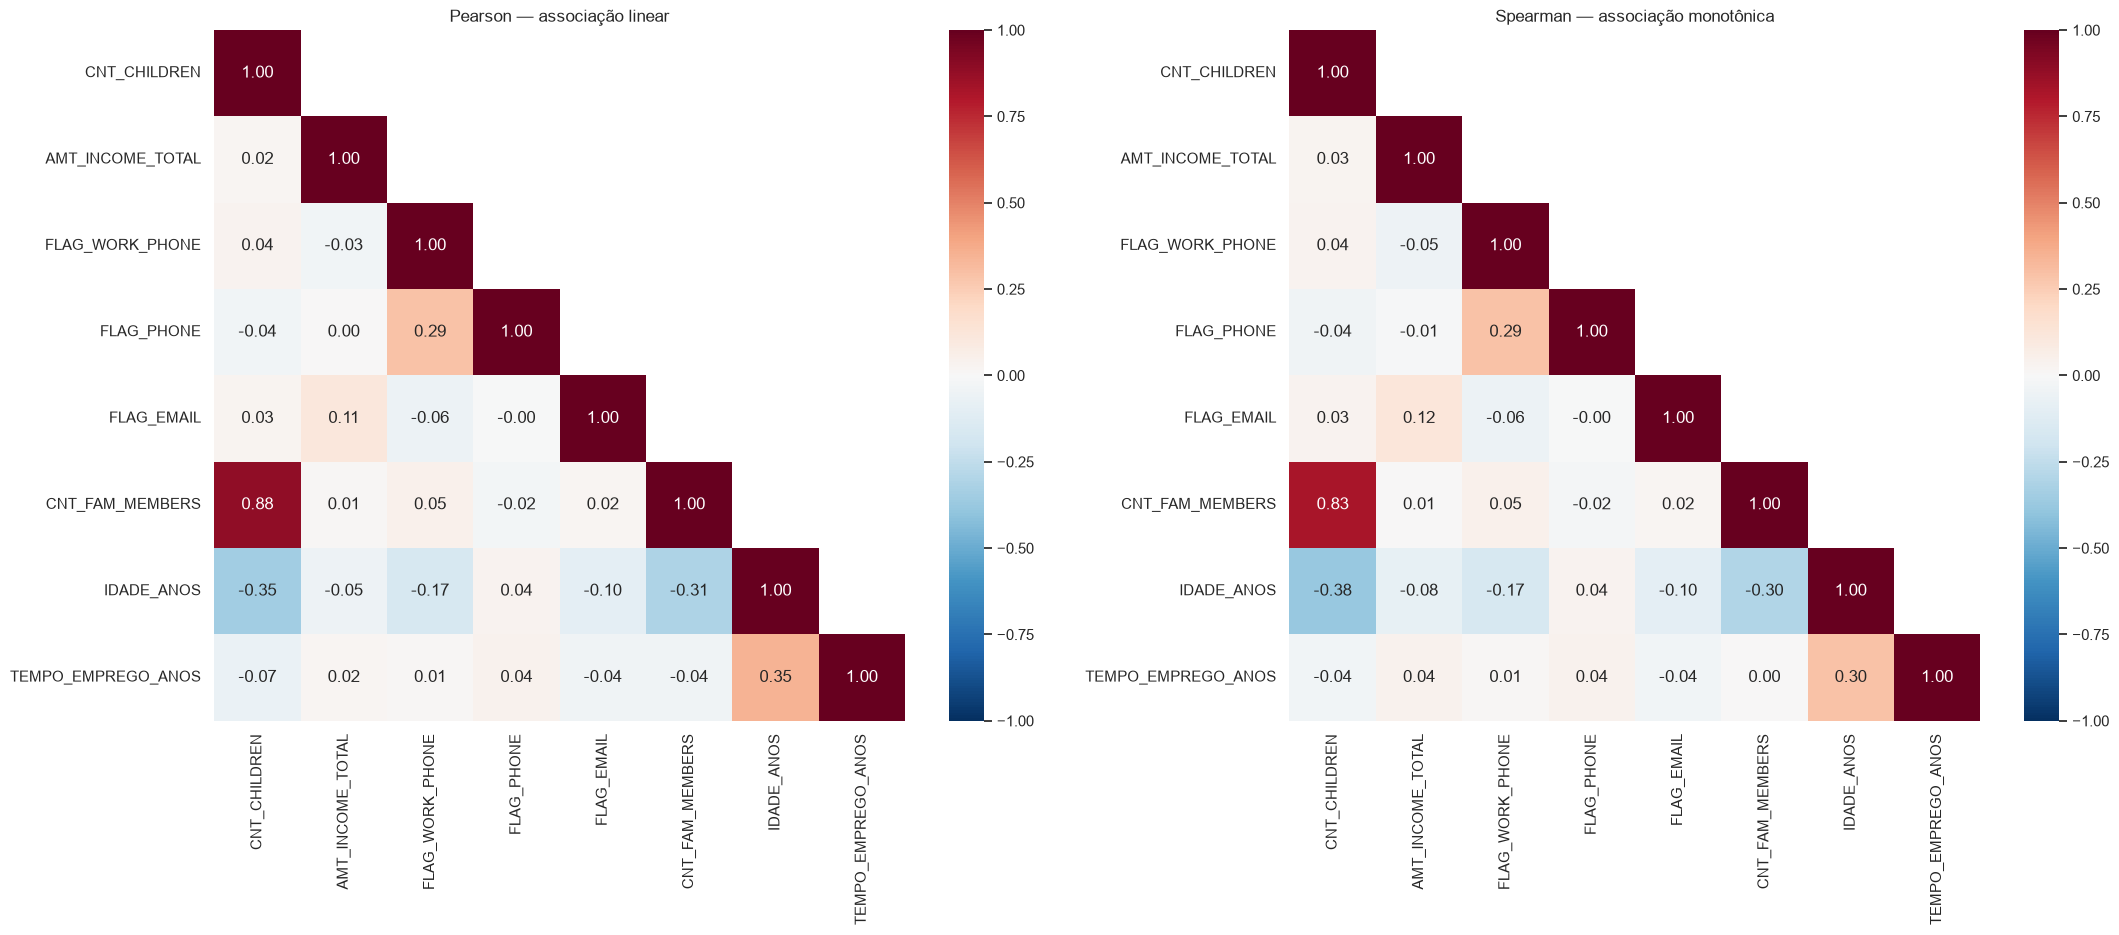


Maiores correlações numéricas — Pearson:


,variavel_1,variavel_2,correlacao,correlacao_absoluta
4,CNT_CHILDREN,CNT_FAM_MEMBERS,0.885,0.885
5,CNT_CHILDREN,IDADE_ANOS,-0.349,0.349
27,IDADE_ANOS,TEMPO_EMPREGO_ANOS,0.348,0.348
25,CNT_FAM_MEMBERS,IDADE_ANOS,-0.306,0.306
13,FLAG_WORK_PHONE,FLAG_PHONE,0.290,0.290
16,FLAG_WORK_PHONE,IDADE_ANOS,-0.172,0.172
9,AMT_INCOME_TOTAL,FLAG_EMAIL,0.112,0.112
23,FLAG_EMAIL,IDADE_ANOS,-0.097,0.097
6,CNT_CHILDREN,TEMPO_EMPREGO_ANOS,-0.070,0.070
14,FLAG_WORK_PHONE,FLAG_EMAIL,-0.061,0.061



Maiores correlações numéricas — Spearman:


,variavel_1,variavel_2,correlacao,correlacao_absoluta
4,CNT_CHILDREN,CNT_FAM_MEMBERS,0.826,0.826
5,CNT_CHILDREN,IDADE_ANOS,-0.382,0.382
25,CNT_FAM_MEMBERS,IDADE_ANOS,-0.304,0.304
27,IDADE_ANOS,TEMPO_EMPREGO_ANOS,0.296,0.296
13,FLAG_WORK_PHONE,FLAG_PHONE,0.290,0.290
16,FLAG_WORK_PHONE,IDADE_ANOS,-0.167,0.167
9,AMT_INCOME_TOTAL,FLAG_EMAIL,0.121,0.121
23,FLAG_EMAIL,IDADE_ANOS,-0.096,0.096
11,AMT_INCOME_TOTAL,IDADE_ANOS,-0.079,0.079
14,FLAG_WORK_PHONE,FLAG_EMAIL,-0.061,0.061



Quantidade de registros usados em cada par numérico:


,CNT_CHILDREN,AMT_INCOME_TOTAL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,IDADE_ANOS,TEMPO_EMPREGO_ANOS
CNT_CHILDREN,438557,438557,438557,438557,438557,438557,438557,363228
AMT_INCOME_TOTAL,438557,438557,438557,438557,438557,438557,438557,363228
FLAG_WORK_PHONE,438557,438557,438557,438557,438557,438557,438557,363228
FLAG_PHONE,438557,438557,438557,438557,438557,438557,438557,363228
FLAG_EMAIL,438557,438557,438557,438557,438557,438557,438557,363228
CNT_FAM_MEMBERS,438557,438557,438557,438557,438557,438557,438557,363228
IDADE_ANOS,438557,438557,438557,438557,438557,438557,438557,363228
TEMPO_EMPREGO_ANOS,363228,363228,363228,363228,363228,363228,363228,363228



Maiores correlações incluindo indicadores de categorias:


,variavel_1,variavel_2,correlacao,correlacao_absoluta
4,CNT_CHILDREN,CNT_FAM_MEMBERS,0.885,0.885
699,NAME_INCOME_TYPE=Pensioner,OCCUPATION_TYPE=<AUSENTE>,0.685,0.685
311,IDADE_ANOS,NAME_INCOME_TYPE=Pensioner,0.621,0.621
274,CNT_FAM_MEMBERS,NAME_FAMILY_STATUS=Married,0.511,0.511
331,IDADE_ANOS,OCCUPATION_TYPE=<AUSENTE>,0.429,0.429
276,CNT_FAM_MEMBERS,NAME_FAMILY_STATUS=Single / not married,-0.427,0.427
5,CNT_CHILDREN,IDADE_ANOS,-0.349,0.349
303,IDADE_ANOS,TEMPO_EMPREGO_ANOS,0.348,0.348
397,CODE_GENDER=F,FLAG_OWN_CAR=Y,-0.347,0.347
396,CODE_GENDER=F,FLAG_OWN_CAR=N,0.347,0.347



Resultados salvos em: d:\GitHub\Tech-Challenge-Fase-2-POSTECH-Data-Analytics\data\processed\analise_correlacao


In [5]:
#ANALISA A TABELA application_record

# ============================================================
# ANÁLISE DE CORRELAÇÃO — application_record
# ============================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carregar a tabela
CAMINHO = RAW / "application_record.csv"

if not CAMINHO.is_file():
    raise FileNotFoundError(f"Arquivo não encontrado: {CAMINHO}")

df = pd.read_csv(CAMINHO)
df.columns = df.columns.str.strip()

print(f"Linhas: {len(df):,} | Colunas: {df.shape[1]}")
display(df.head())

# 2. Diagnóstico inicial
diagnostico = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "ausentes": df.isna().sum(),
    "ausentes_%": df.isna().mean().mul(100).round(2),
    "valores_distintos": df.nunique()
})

print("\nDiagnóstico das colunas:")
display(diagnostico)

print("Linhas completamente duplicadas:", df.duplicated().sum())
if "ID" in df.columns:
    print("IDs repetidos:", df["ID"].duplicated().sum())

# Trabalhar em uma cópia, preservando a tabela original.
dados = df.drop(columns=["ID"], errors="ignore").copy()

# 3. Tratar dias e criar variáveis mais interpretáveis
if "DAYS_BIRTH" in dados.columns:
    dias = pd.to_numeric(dados.pop("DAYS_BIRTH"), errors="coerce")
    # Valores não negativos não representam uma idade válida.
    dados["IDADE_ANOS"] = -dias.where(dias < 0) / 365.25

if "DAYS_EMPLOYED" in dados.columns:
    dias = pd.to_numeric(dados.pop("DAYS_EMPLOYED"), errors="coerce")

    print(
        "Registros com DAYS_EMPLOYED = 365243:",
        int(dias.eq(365243).sum())
    )

    # O código especial não é uma duração real de emprego.
    # Outros valores positivos também ficam ausentes nesta análise.
    dados["TEMPO_EMPREGO_ANOS"] = -dias.where(dias <= 0) / 365.25

# 4. Remover constantes: sua correlação não é definida
constantes = dados.columns[dados.nunique(dropna=True) <= 1].tolist()
dados = dados.drop(columns=constantes)

print("\nColunas constantes removidas:", constantes)

numericas = dados.select_dtypes(include=["number", "bool"]).copy()
numericas = numericas.replace([np.inf, -np.inf], np.nan)

if numericas.shape[1] < 2:
    raise ValueError("São necessárias pelo menos duas colunas numéricas.")

# Os valores ausentes são excluídos por par de variáveis.
# Não preencher com zero, pois isso alteraria as correlações.
pearson = numericas.corr(method="pearson", min_periods=30)
spearman = numericas.corr(method="spearman", min_periods=30)

# Quantidade de observações efetivamente disponíveis em cada par
validos = numericas.notna().astype("int64")
n_por_par = validos.T @ validos

# 5. Mapas de correlação das variáveis numéricas
sns.set_theme(style="white")

fig, axes = plt.subplots(1, 2, figsize=(22, 9))

for ax, matriz, titulo in zip(
    axes,
    [pearson, spearman],
    ["Pearson — associação linear", "Spearman — associação monotônica"]
):
    mascara = np.triu(np.ones(matriz.shape, dtype=bool), k=1)
    sns.heatmap(
        matriz,
        mask=mascara,
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        ax=ax
    )
    ax.set_title(titulo)
    ax.tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

# 6. Função para listar os pares de maior correlação absoluta
def listar_pares(matriz, origens=None):
    linhas = []

    for i, coluna_a in enumerate(matriz.columns):
        for j in range(i + 1, len(matriz.columns)):
            coluna_b = matriz.columns[j]
            valor = matriz.iloc[i, j]

            if pd.isna(valor):
                continue

            # Evitar listar associações entre categorias da mesma coluna:
            # elas são mutuamente exclusivas por construção.
            if origens and origens[coluna_a] == origens[coluna_b]:
                continue

            linhas.append({
                "variavel_1": coluna_a,
                "variavel_2": coluna_b,
                "correlacao": valor,
                "correlacao_absoluta": abs(valor)
            })

    return pd.DataFrame(
        linhas,
        columns=[
            "variavel_1", "variavel_2",
            "correlacao", "correlacao_absoluta"
        ]
    ).sort_values("correlacao_absoluta", ascending=False)

print("\nMaiores correlações numéricas — Pearson:")
display(listar_pares(pearson).head(20).round(3))

print("\nMaiores correlações numéricas — Spearman:")
display(listar_pares(spearman).head(20).round(3))

print("\nQuantidade de registros usados em cada par numérico:")
display(n_por_par)

# 7. Incluir variáveis categóricas como indicadores 0/1
# Cada categoria vira uma coluna própria, por exemplo:
# FLAG_OWN_CAR=N e FLAG_OWN_CAR=Y.
categoricas = dados.select_dtypes(exclude=["number", "bool"]).columns

blocos = [numericas]
origens = {coluna: coluna for coluna in numericas.columns}

for coluna in categoricas:
    categorias = dados[coluna].astype("string").fillna("<AUSENTE>")
    indicadores = pd.get_dummies(
        categorias,
        prefix=coluna,
        prefix_sep="=",
        dtype="int8"
    )

    blocos.append(indicadores)
    origens.update({nome: coluna for nome in indicadores.columns})

expandida = pd.concat(blocos, axis=1)
expandida = expandida.loc[:, expandida.nunique(dropna=True) > 1]

correlacao_expandida = expandida.corr(
    method="pearson",
    min_periods=30
)

pares_expandida = listar_pares(correlacao_expandida, origens)

print("\nMaiores correlações incluindo indicadores de categorias:")
display(pares_expandida.head(30).round(3))

# 8. Salvar resultados em uma pasta própria
SAIDA = PROCESSED / "analise_correlacao"
SAIDA.mkdir(parents=True, exist_ok=True)

diagnostico.to_csv(SAIDA / "diagnostico.csv")
pearson.to_csv(SAIDA / "correlacao_pearson.csv")
spearman.to_csv(SAIDA / "correlacao_spearman.csv")
n_por_par.to_csv(SAIDA / "observacoes_por_par.csv")
correlacao_expandida.to_csv(SAIDA / "correlacao_com_categorias.csv")
pares_expandida.to_csv(SAIDA / "pares_correlacionados.csv", index=False)

print(f"\nResultados salvos em: {SAIDA}")

**Leitura (resultados do Colab):**

- 438.557 linhas e 18 colunas; 47 IDs repetidos; `OCCUPATION_TYPE` tem 30,6% de ausentes.
- 75.329 registros com `DAYS_EMPLOYED = 365243`, valor-código que não é tempo de emprego.
- `FLAG_MOBIL` é constante (sem informação).
- Só um par é fortemente correlacionado: `CNT_CHILDREN` × `CNT_FAM_MEMBERS` (0,89). As demais associações ficam abaixo de 0,35, o que indica sinal cadastral fraco.

## 4. Histórico de crédito: status e balanceamento das classes

Diagnóstico da tabela `credit_record`: validação de chaves, distribuição de `STATUS`, duração do histórico e percentual de clientes com atraso por severidade.

In [6]:
#ANALISE INICIAL DA TABELA credit_record

import argparse
from pathlib import Path
import pandas as pd

ENTRADA = RAW / "credit_record.csv"
STATUS = ['0', '1', '2', '3', '4', '5', 'C', 'X']


def resumir(df):
    """Entrada já validada, com uma observação por cliente/mês."""
    df = df.sort_values(['ID', 'MONTHS_BALANCE']).copy()
    g = df.groupby('ID', sort=True)
    r = g.MONTHS_BALANCE.agg(primeiro_mes='min', ultimo_mes='max', meses_registrados='size')
    r['intervalo_meses'] = r.ultimo_mes - r.primeiro_mes + 1
    r['lacunas'] = r.intervalo_meses - r.meses_registrados
    r['meses_desde_ultimo_registro'] = -r.ultimo_mes
    counts = pd.crosstab(df.ID, df.STATUS).reindex(index=r.index, columns=STATUS, fill_value=0)
    for s in STATUS:
        r['meses_status_' + s] = counts[s]
    r['meses_com_credito_observado'] = r.meses_registrados - counts.X
    r['somente_X'] = counts.X.eq(r.meses_registrados)
    r['somente_C'] = counts.C.eq(r.meses_registrados)
    r['somente_C_ou_X'] = (counts.C + counts.X).eq(r.meses_registrados)
    numeric = pd.to_numeric(df.STATUS, errors='coerce')
    r['pior_status_numerico'] = numeric.groupby(df.ID).max().astype('Int64')
    r['ultimo_status'] = g.STATUS.last()
    for threshold, label in [(0, '1mais'), (1, '30mais'), (2, '60mais'), (3, '90mais')]:
        flag = numeric.ge(threshold)
        r['meses_atraso_' + label] = flag.groupby(df.ID).sum().astype(int)
        r['teve_atraso_' + label] = r['meses_atraso_' + label].gt(0)
        # X não é exposição; C permanece no denominador de crédito observado.
        r['proporcao_atraso_' + label] = r['meses_atraso_' + label] / r.meses_com_credito_observado.replace(0, float('nan'))
        r['ultimo_mes_atraso_' + label] = df.MONTHS_BALANCE.where(flag).groupby(df.ID).max().astype('Int64')
        # Quebrar sequências nas lacunas, mudanças de cliente e meses sem atraso.
        boundary = df.ID.ne(df.ID.shift()) | df.MONTHS_BALANCE.diff().ne(1) | ~flag | ~flag.shift(fill_value=False)
        runs = pd.DataFrame({'ID': df.ID, 'run': boundary.cumsum(), 'flag': flag})
        maximum = runs.groupby(['ID', 'run']).flag.sum().groupby(level=0).max()
        r['maior_sequencia_atraso_' + label] = maximum.reindex(r.index, fill_value=0).astype(int)
    return r.reset_index()


def executar(entrada=ENTRADA, exibir=True):
    """Retorna um dicionário com diagnóstico e DataFrames

    Em caso de erro, exibe até 10 registros para revisão e interrompe a
    agregação. Não preenche lacunas nem remove registros automaticamente.
    """
    entrada = Path(entrada)
    if not entrada.is_file():
        raise FileNotFoundError(
            f'Arquivo não encontrado: {entrada}. '
            'Confira se o CSV está em data/raw/.'
        )
    df = pd.read_csv(entrada, dtype='string', keep_default_na=False)
    obrigatorias = ['ID', 'MONTHS_BALANCE', 'STATUS']
    ausentes = set(obrigatorias) - set(df.columns)
    if ausentes:
        raise ValueError('Colunas obrigatórias ausentes: ' + str(sorted(ausentes)))
    df = df[obrigatorias].copy()
    if df.empty:
        raise ValueError('A tabela não contém registros.')
    invalid = df.apply(lambda col: col.str.strip().eq('')).any(axis=1)
    valores_mes = pd.to_numeric(df.MONTHS_BALANCE, errors='coerce')
    for col in ['ID', 'MONTHS_BALANCE']:
        value = pd.to_numeric(df[col], errors='coerce')
        invalid |= value.isna() | value.mod(1).ne(0)
        invalid |= value.le(0) if col == 'ID' else value.gt(0)
    invalid |= ~df.STATUS.isin(STATUS)
    # A chave usa o mês numérico: '-01' e '-1' representam o mesmo mês.
    chaves = pd.DataFrame({'ID': df.ID, 'mes': valores_mes})
    duplicate_keys = chaves.duplicated(['ID', 'mes'], keep=False)
    if invalid.any() or duplicate_keys.any():
        revisao = df.loc[invalid | duplicate_keys].copy()
        revisao['linha_invalida'] = invalid.loc[revisao.index]
        revisao['chave_repetida'] = duplicate_keys.loc[revisao.index]
        print('Amostra de registros para revisão:')
        print(revisao.head(10).to_string(index=False))
        raise ValueError(
            f'Agregação interrompida: {invalid.sum()} linhas inválidas; '
            f'{duplicate_keys.sum()} linhas com chave repetida. '
            'Nenhuma correção automática aplicada.'
        )
    df['MONTHS_BALANCE'] = valores_mes.astype('int64')
    # IDs ficam em texto para preservar possíveis zeros iniciais.
    r = resumir(df)
    assert r.ID.is_unique and r.meses_registrados.sum() == len(df)
    assert (r.lacunas >= 0).all()
    assert r[['meses_status_' + s for s in STATUS]].sum(axis=1).eq(r.meses_registrados).all()
    dist = df.STATUS.value_counts().reindex(STATUS, fill_value=0).rename_axis('STATUS').to_frame('registros')
    dist['percentual_registros'] = dist.registros / len(df) * 100
    dist['clientes_com_status'] = [int(r['meses_status_' + s].gt(0).sum()) for s in STATUS]
    dist['percentual_clientes'] = dist.clientes_com_status / len(r) * 100
    monthly = pd.crosstab(df.MONTHS_BALANCE, df.STATUS).reindex(columns=STATUS, fill_value=0)
    monthly['clientes_observados'] = monthly.sum(axis=1)
    d = {'arquivo': str(entrada),
         'linhas': len(df), 'clientes': len(r), 'mes_inicial': int(df.MONTHS_BALANCE.min()), 'mes_final': int(df.MONTHS_BALANCE.max()),
         'linhas_invalidas': 0, 'chaves_repetidas': 0,
         'clientes_com_lacunas': int(r.lacunas.gt(0).sum()), 'lacunas_totais': int(r.lacunas.sum()),
         'clientes_terminam_antes_mes_zero': int(r.ultimo_mes.lt(0).sum()),
         'clientes_somente_X': int(r.somente_X.sum()), 'clientes_somente_C': int(r.somente_C.sum()),
         'clientes_somente_C_ou_X': int(r.somente_C_ou_X.sum()),
         'clientes_menos_6_meses': int(r.meses_registrados.lt(6).sum()),
         'clientes_menos_12_meses': int(r.meses_registrados.lt(12).sum()),
         'meses_registrados_descritiva': r.meses_registrados.describe().to_dict(),
         'clientes_com_atraso': {label: int(r['teve_atraso_' + label].sum()) for label in ['1mais', '30mais', '60mais', '90mais']}}
    atrasos = pd.DataFrame([
        {'corte': label, 'clientes': n, 'percentual_clientes': 100 * n / len(r)}
        for label, n in d['clientes_com_atraso'].items()
    ])
    resultados = {
        'diagnostico': d,
        'resumo_por_cliente': r,
        'distribuicao_status': dist,
        'distribuicao_mensal': monthly,
        'clientes_com_atraso': atrasos,
        'duracao_historico': r.meses_registrados.describe(),
    }
    if exibir:
        exibir_resultados(resultados)
    return resultados


def exibir_resultados(resultados):
    """Exibe tabelas no notebook ou imprime no terminal."""
    def mostrar(tabela):
        try:
            from IPython import get_ipython
            from IPython.display import display
            if get_ipython() is not None:
                display(tabela)
                return
        except ImportError:
            pass
        print(tabela.to_string())

    d = resultados['diagnostico']
    print('DIAGNÓSTICO DA TABELA')
    mostrar(pd.Series({k: v for k, v in d.items() if not isinstance(v, dict)}, name='resultado').to_frame())
    for titulo, chave in [
        ('DISTRIBUIÇÃO DOS STATUS', 'distribuicao_status'),
        ('CLIENTES COM ATRASO EM ALGUM MÊS', 'clientes_com_atraso'),
        ('DURAÇÃO DOS HISTÓRICOS', 'duracao_historico'),
        ('DISTRIBUIÇÃO MENSAL', 'distribuicao_mensal'),
    ]:
        print('\n' + titulo)
        mostrar(resultados[chave])
    print('\nRESUMO POR CLIENTE — primeiros 10 clientes')
    mostrar(resultados['resumo_por_cliente'].head(10))
    print('\nResumo completo disponível em resumo_por_cliente. Proporções entre 0 e 1.')
    print('Os cortes de atraso se sobrepõem; clientes com status diferentes também.')


def em_notebook():
    try:
        from IPython import get_ipython
        return get_ipython() is not None
    except ImportError:
        return False


if __name__ == '__main__':
    if em_notebook():
        entrada = ENTRADA
    else:
        parser = argparse.ArgumentParser(description=__doc__)
        parser.add_argument('entrada', nargs='?', default=ENTRADA)
        entrada = parser.parse_args().entrada
    resultados = executar(entrada)
    # Disponíveis no namespace da célula ou após %run (Jupyter/Colab).
    diagnostico = resultados['diagnostico']
    resumo_por_cliente = resultados['resumo_por_cliente']
    distribuicao_status = resultados['distribuicao_status']
    distribuicao_mensal = resultados['distribuicao_mensal']
    clientes_com_atraso = resultados['clientes_com_atraso']
    duracao_historico = resultados['duracao_historico']

DIAGNÓSTICO DA TABELA


,resultado
arquivo,d:\GitHub\Tech-Challenge-Fase-2-POSTECH-Data-A...
linhas,1048575
clientes,45985
mes_inicial,-60
mes_final,0
linhas_invalidas,0
chaves_repetidas,0
clientes_com_lacunas,0
lacunas_totais,0
clientes_terminam_antes_mes_zero,12129



DISTRIBUIÇÃO DOS STATUS


,registros,percentual_registros,clientes_com_status,percentual_clientes
STATUS,,,,
0,383120,36.537205,39980,86.941394
1,11090,1.057626,5201,11.310210
2,868,0.082779,597,1.298249
3,320,0.030518,268,0.582799
4,223,0.021267,190,0.413178
5,1693,0.161457,195,0.424051
C,442031,42.155401,22707,49.379145
X,209230,19.953747,25005,54.376427



CLIENTES COM ATRASO EM ALGUM MÊS


...


DISTRIBUIÇÃO MENSAL


STATUS,0,1,2,3,4,5,C,X,clientes_observados
MONTHS_BALANCE,,,,,,,,,
-60,230,0,0,0,0,0,1,184,415
-59,538,3,0,0,0,0,9,270,820
-58,850,11,0,0,0,0,24,370,1255
-57,1120,17,0,0,0,0,52,460,1649
-56,1416,28,2,0,0,0,91,572,2109
...,...,...,...,...,...,...,...,...,...
-4,10491,379,21,5,8,54,16403,6004,33365
-3,10610,313,31,6,5,54,16784,6051,33854
-2,10398,367,19,11,3,57,17139,6215,34209



RESUMO POR CLIENTE — primeiros 10 clientes


,ID,primeiro_mes,ultimo_mes,meses_registrados,intervalo_meses,lacunas,meses_desde_ultimo_registro,meses_status_0,meses_status_1,meses_status_2,...,meses_atraso_60mais,teve_atraso_60mais,proporcao_atraso_60mais,ultimo_mes_atraso_60mais,maior_sequencia_atraso_60mais,meses_atraso_90mais,teve_atraso_90mais,proporcao_atraso_90mais,ultimo_mes_atraso_90mais,maior_sequencia_atraso_90mais
0,5001711,-3,0,4,4,0,0,3,0,0,...,0,False,0.0,<NA>,0,0,False,0.0,<NA>,0
1,5001712,-18,0,19,19,0,0,10,0,0,...,0,False,0.0,<NA>,0,0,False,0.0,<NA>,0
2,5001713,-21,0,22,22,0,0,0,0,0,...,0,False,NaN,<NA>,0,0,False,NaN,<NA>,0
3,5001714,-14,0,15,15,0,0,0,0,0,...,0,False,NaN,<NA>,0,0,False,NaN,<NA>,0
4,5001715,-59,0,60,60,0,0,0,0,0,...,0,False,NaN,<NA>,0,0,False,NaN,<NA>,0
5,5001717,-21,0,22,22,0,0,17,0,0,...,0,False,0.0,<NA>,0,0,False,0.0,<NA>,0
6,5001718,-38,0,39,39,0,0,24,2,0,...,0,False,0.0,<NA>,0,0,False,0.0,<NA>,0
7,5001719,-42,0,43,43,0,0,2,0,0,...,0,False,0.0,<NA>,0,0,False,0.0,<NA>,0
8,5001720,-35,0,36,36,0,0,29,7,0,...,0,False,0.0,<NA>,0,0,False,0.0,<NA>,0
9,5001723,-30,0,31,31,0,0,8,0,0,...,0,False,0.0,<NA>,0,0,False,0.0,<NA>,0



Resumo completo disponível em resumo_por_cliente. Proporções entre 0 e 1.
Os cortes de atraso se sobrepõem; clientes com status diferentes também.


**Leitura (resultados do Colab):**

- 1.048.575 registros de 45.985 clientes, com até 61 meses de histórico (média de 22,8) e nenhuma lacuna interna.
- 4.536 clientes têm somente `X` (nunca tiveram crédito) e serão excluídos em `02_preprocessamento.ipynb`.
- **Balanceamento:** 87,1% dos clientes têm algum mês com 1+ dia de atraso, mas apenas 11,6% chegam a 30+ dias, 1,45% a 60+ dias e 0,72% a 90+ dias. Quanto mais grave o atraso, mais raro o evento.